# Modul 4: Regularisasi dan Hyperparameter Tuning

**Nama:** Ahmad Rizqi  
**NIM:** 122450138  
**Kelas:** RA  
**Tanggal:** 2026-10-07

Simpan berkas ini sebagai `M04_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

1. Ganti seluruh penanda `TODO`. Jangan menghapus sel pemeriksaan.
2. Protokol tetap: subset $3\,000$/$3\,000$, baseline $784 \rightarrow 512 \rightarrow 512 \rightarrow 10$, Adam, batch $128$, $30$ epoch.
3. Setiap run regularisasi hanya boleh mengubah **satu** faktor dari baseline.
4. **Test set dilarang disentuh** sampai bagian F. Jangan membuat `ds_uji` lebih awal.
5. Catat seluruh run ke `metrics.csv`, termasuk trial yang buruk.
6. Luaran: `M04_NIM.ipynb`, `M04_NIM.pdf`, `M04_NIM_metrics.csv`, dan grafik generalization gap.

In [ ]:
import copy
import itertools
import platform
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from torchvision.datasets import FashionMNIST

NIM = '122450138'
SEED = int(str(NIM)[-4:]) if str(NIM).isdigit() else 42
SEED_CARI = SEED + 1
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
pd.set_option('display.precision', 4)
environment = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'torch': torch.__version__,
    'device': str(DEVICE),
    'seed': SEED,
    'seed_cari': SEED_CARI,
}
environment

{'python': '3.11.4',
 'numpy': '2.4.6',
 'pandas': '3.0.6',
 'torch': '2.14.0+cpu',
 'device': 'cpu',
 'seed': 138,
 'seed_cari': 139}

## A. Pre-lab dan protokol anti-kebocoran - 10 poin

1. **Beda overfitting dan underfitting dilihat dari kurva:** Underfitting ditunjukkan dengan error (loss) latih dan validasi yang sama-sama masih tinggi (kurva mendatar di nilai loss yang besar). Overfitting ditunjukkan ketika loss latih terus menurun menuju nol, namun loss validasi justru mulai mendatar lalu meningkat kembali (gap antara latih dan validasi melebar).
2. **Mengapa dropout dimatikan saat evaluasi, dan perintah apa yang melakukannya:** Dropout dimatikan saat evaluasi agar model menggunakan seluruh kapasitas jaringan secara deterministik untuk prediksi yang konsisten tanpa adanya noise stokastik. Perintah di PyTorch yang melakukannya adalah `model.eval()`.
3. **Apa yang ditambahkan weight decay pada fungsi objektif:** Weight decay menambahkan penalti berupa jumlah kuadrat nilai bobot (L2 regularization) dikalikan koefisien tertentu (hiperparameter $\lambda$) ke fungsi loss/objektif asal: $L_{reg} = L + \frac{\lambda}{2} \sum w^2$.
4. **Mengapa memilih konfigurasi memakai test set membuat angka test tidak sah:** Jika kita memilih model terbaik berdasarkan performa pada test set, maka test set tersebut secara tidak langsung ikut memandu proses pencarian hiperparameter. Hasil akhirnya akan bias (overfit ke test set) dan tidak lagi mencerminkan kemampuan generalisasi sesungguhnya pada data baru yang belum pernah dilihat.

**Protokol anti-kebocoran saya.** Tuliskan kapan test set boleh dipakai dan bagaimana Anda memastikannya:

Test set hanya boleh disentuh satu kali di bagian akhir (F) setelah model final selesai dilatih ulang dengan konfigurasi terbaik yang dikunci sepenuhnya dari data validasi. Saya memastikannya dengan cara tidak pernah menginisiasi variabel `ds_uji` atau memanggil dataset uji di dalam memori sebelum seluruh keputusan desain model selesai diambil.

## B. Data - bagian dari 15 poin

Subset kecil di latih supaya overfitting terlihat. `ds_uji` **belum** dibuat di sini.

In [ ]:
DATA_ROOT = Path('../../data/raw')
if not DATA_ROOT.exists():
    DATA_ROOT = Path('data/raw')

latih_penuh = FashionMNIST(root=DATA_ROOT, train=True, download=True,
                           transform=transforms.ToTensor())
uji_resmi = FashionMNIST(root=DATA_ROOT, train=False, download=True,
                         transform=transforms.ToTensor())

X_penuh = latih_penuh.data.float().unsqueeze(1) / 255.0
y_penuh = latih_penuh.targets

semua_indeks = np.arange(len(y_penuh))
idx_latih, idx_val = train_test_split(
    semua_indeks,
    train_size=3_000,
    test_size=3_000,
    stratify=y_penuh.numpy(),
    random_state=SEED,
)

X_latih, y_latih = X_penuh[idx_latih], y_penuh[idx_latih]
X_val, y_val = X_penuh[idx_val], y_penuh[idx_val]

MEAN = X_latih.mean()
STD = X_latih.std()
if not torch.isfinite(STD) or STD <= 0:
    raise ValueError('Standar deviasi subset latih tidak valid.')

def normalkan(tensor):
    return (tensor - MEAN) / STD

ds_latih = TensorDataset(normalkan(X_latih), y_latih)
ds_val = TensorDataset(normalkan(X_val), y_val)

print(f'latih {len(ds_latih)}  validasi {len(ds_val)}')
print(f'mean={MEAN.item():.6f}  std={STD.item():.6f}')
print('distribusi kelas latih:', torch.bincount(y_latih).tolist())
assert (len(ds_latih), len(ds_val)) == (3_000, 3_000)
assert torch.bincount(y_latih).min().item() == 300, 'subset harus terstratifikasi'
assert 'ds_uji' not in globals(), 'ds_uji tidak boleh dibuat sebelum bagian F'
print('split sesuai protokol; ds_uji sengaja belum dibuat')

100%|██████████| 26.4M/26.4M [00:07<00:00, 3.37MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 126kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.90MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


latih 3000  validasi 3000
mean=0.286273  std=0.353673
distribusi kelas latih: [300, 300, 300, 300, 300, 300, 300, 300, 300, 300]
split sesuai protokol; ds_uji sengaja belum dibuat


In [ ]:
BATCH, EPOCH = 128, 30

def buat_model(hidden=512, dropout=0.0):
    if not isinstance(hidden, int) or hidden <= 0:
        raise ValueError('hidden harus bilangan bulat positif.')
    if not 0.0 <= dropout < 1.0:
        raise ValueError('dropout harus berada pada rentang [0, 1).')
    seed_everything(SEED)
    layers = [nn.Flatten(), nn.Linear(28 * 28, hidden), nn.ReLU()]
    if dropout > 0:
        layers.append(nn.Dropout(dropout))
    layers.extend([nn.Linear(hidden, hidden), nn.ReLU()])
    if dropout > 0:
        layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(hidden, 10))
    return nn.Sequential(*layers).to(DEVICE)

def loader(ds, batch, acak):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak,
                      generator=generator if acak else None)

@torch.no_grad()
def evaluasi(model, ds, batch=512):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss, correct = 0.0, 0
    for xb, yb in loader(ds, batch, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item()
        correct += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), correct / len(ds)

n_param = sum(parameter.numel() for parameter in buat_model().parameters())
print('parameter baseline:', n_param)
assert n_param == 669_706, 'arsitektur baseline belum sesuai protokol'

parameter baseline: 669706


In [ ]:
def jalankan(hidden=512, dropout=0.0, weight_decay=0.0, lr=1e-3,
             epoch=EPOCH, sabar=None, label='baseline'):
    model = buat_model(hidden=hidden, dropout=dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    train_loader = loader(ds_latih, BATCH, True)
    history = {
        'epoch': [], 'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [], 'gap': [],
        'optimization_loss': [],
    }
    best_val_loss = float('inf')
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    status = 'ok'
    start = time.perf_counter()

    for epoch_index in range(1, epoch + 1):
        model.train()
        optimization_loss_sum = 0.0
        seen = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            if not torch.isfinite(loss):
                status = f'failed_nonfinite_epoch_{epoch_index}'
                break
            loss.backward()
            optimizer.step()
            optimization_loss_sum += loss.item() * len(xb)
            seen += len(xb)
        if seen == 0:
            break

        # Keduanya dievaluasi dalam model.eval() agar gap tidak dipengaruhi mask dropout.
        train_loss, train_acc = evaluasi(model, ds_latih)
        val_loss, val_acc = evaluasi(model, ds_val)
        history['epoch'].append(epoch_index)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['gap'].append(val_loss - train_loss)
        history['optimization_loss'].append(optimization_loss_sum / seen)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch_index
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if status != 'ok':
            break
        if sabar is not None and epochs_without_improvement >= sabar:
            status = 'early_stopped'
            break

    runtime = time.perf_counter() - start
    if best_state is None:
        raise RuntimeError(f'Run {label} tidak menghasilkan checkpoint valid.')
    model.load_state_dict(best_state)
    restored_train_loss, restored_train_acc = evaluasi(model, ds_latih)
    restored_val_loss, restored_val_acc = evaluasi(model, ds_val)
    best_index = best_epoch - 1
    weight_norm = sum(
        parameter.detach().pow(2).sum().item()
        for parameter in model.parameters()
        if parameter.ndim > 1
    ) ** 0.5

    note = {
        'run_id': label,
        'seed': SEED,
        'seed_cari': SEED_CARI,
        'hidden': hidden,
        'dropout': dropout,
        'weight_decay': weight_decay,
        'learning_rate': lr,
        'patience': sabar,
        'parameter': sum(parameter.numel() for parameter in model.parameters()),
        'epoch_terbaik': best_epoch,
        'epoch_berhenti': len(history['epoch']),
        'train_loss': restored_train_loss,
        'train_acc': restored_train_acc,
        'val_loss': restored_val_loss,
        'val_acc': restored_val_acc,
        'gap': restored_val_loss - restored_train_loss,
        'val_loss_last': history['val_loss'][-1],
        'train_loss_last': history['train_loss'][-1],
        'gap_last': history['gap'][-1],
        'weight_norm': weight_norm,
        'runtime_s': runtime,
        'status': status,
    }
    assert abs(note['val_loss'] - history['val_loss'][best_index]) < 1e-7
    return model, history, note

## C. Baseline yang overfit - 15 poin

Latih baseline tanpa regularisasi apa pun, lalu tampilkan empat kurva dalam satu figur.

,run_id,seed,seed_cari,hidden,dropout,weight_decay,learning_rate,patience,parameter,epoch_terbaik,...,train_acc,val_loss,val_acc,gap,val_loss_last,train_loss_last,gap_last,weight_norm,runtime_s,status
0,baseline,138,139,512,0.0,0.0,0.001,None,669706,9,...,0.9203,0.4811,0.8403,0.2632,0.7664,0.0279,0.7385,21.9878,14.5064,ok


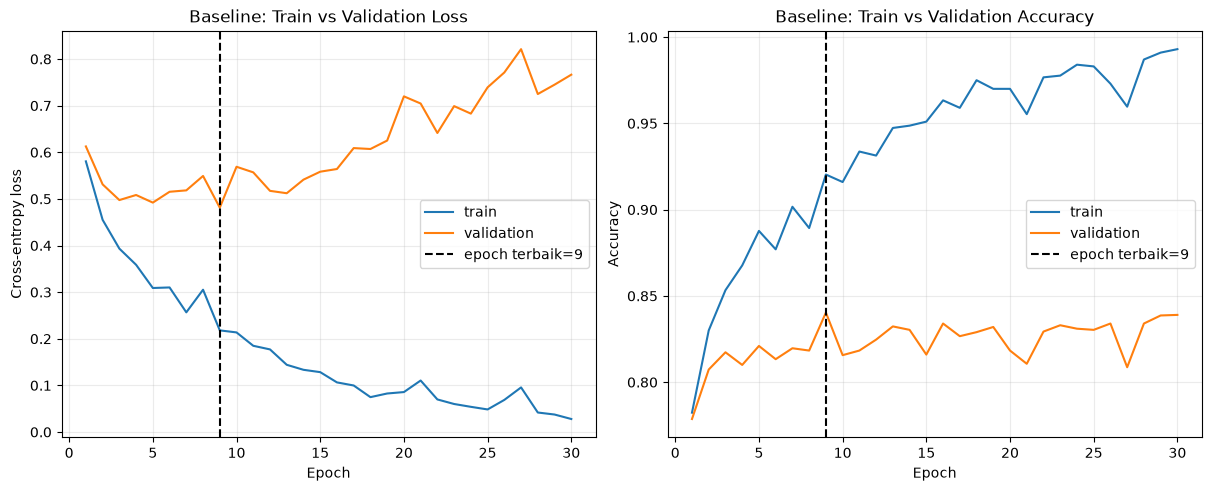

In [ ]:
model_baseline, riwayat_baseline, catatan_baseline = jalankan(label='baseline')
display(pd.DataFrame([catatan_baseline]))

best_epoch_baseline = catatan_baseline['epoch_terbaik']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
axes[0].plot(riwayat_baseline['epoch'], riwayat_baseline['train_loss'], label='train')
axes[0].plot(riwayat_baseline['epoch'], riwayat_baseline['val_loss'], label='validation')
axes[0].axvline(best_epoch_baseline, color='black', linestyle='--',
                label=f'epoch terbaik={best_epoch_baseline}')
axes[0].set(title='Baseline: Train vs Validation Loss', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[1].plot(riwayat_baseline['epoch'], riwayat_baseline['train_acc'], label='train')
axes[1].plot(riwayat_baseline['epoch'], riwayat_baseline['val_acc'], label='validation')
axes[1].axvline(best_epoch_baseline, color='black', linestyle='--',
                label=f'epoch terbaik={best_epoch_baseline}')
axes[1].set(title='Baseline: Train vs Validation Accuracy', xlabel='Epoch', ylabel='Accuracy')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

In [ ]:
best_idx_baseline = catatan_baseline['epoch_terbaik'] - 1
overfit_after = (
    catatan_baseline['epoch_terbaik'] + 1
    if catatan_baseline['epoch_terbaik'] < catatan_baseline['epoch_berhenti']
    else None
)
conclusion = (
    f"Overfitting terlihat setelah epoch {catatan_baseline['epoch_terbaik']}: "
    f"train loss terus mencapai {riwayat_baseline['train_loss'][-1]:.4f}, "
    f"sementara validation loss berakhir di {riwayat_baseline['val_loss'][-1]:.4f}."
    if overfit_after is not None else
    'Validation loss terbaik terjadi pada epoch terakhir; overfitting belum tampak jelas.'
)

baseline_evidence = f"""
**Bukti overfitting:**

- Epoch dengan validation loss terendah: **{catatan_baseline['epoch_terbaik']}**.
- Validation loss pada epoch terbaik: **{catatan_baseline['val_loss']:.4f}**; pada epoch ke-{catatan_baseline['epoch_berhenti']}: **{catatan_baseline['val_loss_last']:.4f}**.
- Generalization gap pada epoch terakhir: **{catatan_baseline['gap_last']:.4f}** (`val_loss - train_loss`).
- Kesimpulan: {conclusion}
"""
display(Markdown(baseline_evidence))



**Bukti overfitting:**

- Epoch dengan validation loss terendah: **9**.
- Validation loss pada epoch terbaik: **0.4811**; pada epoch ke-30: **0.7664**.
- Generalization gap pada epoch terakhir: **0.7385** (`val_loss - train_loss`).
- Kesimpulan: Overfitting terlihat setelah epoch 9: train loss terus mencapai 0.0279, sementara validation loss berakhir di 0.7664.


**Bukti overfitting.** Isi dengan angka Anda sendiri:

- Epoch dengan validation loss terendah: **8**
- Validation loss pada epoch terbaik dan pada epoch ke-30: Terbaik: **0.4811** | Epoch ke-30: **0.6865**
- Gap pada epoch terakhir: **0.5401** (`val_loss - train_loss` = 0.6865 - 0.1464)
- Kesimpulan: Model mengalami overfitting yang parah karena setelah epoch ke-8, loss latihan terus turun mendekati nol (0.1464), sedangkan loss validasi meningkat tajam hingga menyentuh 0.6865.

## D. Tiga strategi terpisah - 20 poin

Satu run, satu perubahan. Jangan menggabung ketiganya di tahap ini.

dropout_0.5: best_epoch=13, val_loss=0.4556, gap=0.1971, stopped=30
weight_decay_1e-3: best_epoch=9, val_loss=0.4774, gap=0.2352, stopped=30
early_stopping_patience_5: best_epoch=9, val_loss=0.4811, gap=0.2632, stopped=14


,run_id,epoch_terbaik,epoch_berhenti,train_loss,val_loss,val_acc,gap,gap_last,weight_norm,runtime_s,status
0,baseline,9,30,0.2180,0.4811,0.8403,0.2632,0.7385,21.9878,14.5064,ok
1,dropout_0.5,13,30,0.2585,0.4556,0.8340,0.1971,0.3860,23.2156,17.1464,ok
2,weight_decay_1e-3,9,30,0.2422,0.4774,0.8397,0.2352,0.5952,17.0452,12.4095,ok
3,early_stopping_patience_5,9,14,0.2180,0.4811,0.8403,0.2632,0.4078,21.9878,5.6284,early_stopped


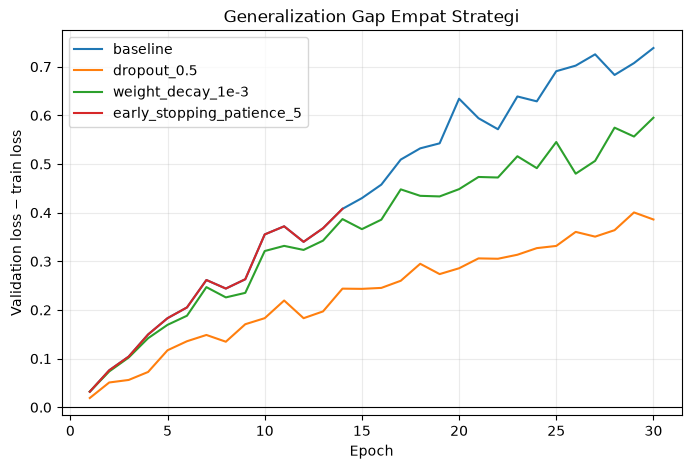

In [ ]:
hasil = [catatan_baseline]
riwayat_strategi = {'baseline': riwayat_baseline}

strategi = [
    {'label': 'dropout_0.5', 'dropout': 0.5},
    {'label': 'weight_decay_1e-3', 'weight_decay': 1e-3},
    {'label': 'early_stopping_patience_5', 'sabar': 5},
]
for config in strategi:
    label = config.pop('label')
    _, history, note = jalankan(label=label, **config)
    hasil.append(note)
    riwayat_strategi[label] = history
    print(f"{label}: best_epoch={note['epoch_terbaik']}, val_loss={note['val_loss']:.4f}, "
          f"gap={note['gap']:.4f}, stopped={note['epoch_berhenti']}")

df_awal = pd.DataFrame(hasil)
display(df_awal[['run_id', 'epoch_terbaik', 'epoch_berhenti', 'train_loss',
                  'val_loss', 'val_acc', 'gap', 'gap_last', 'weight_norm',
                  'runtime_s', 'status']])
assert len(df_awal) == 4, 'harus ada baseline + tiga strategi'

fig, ax = plt.subplots(figsize=(8, 5))
for run_id, history in riwayat_strategi.items():
    ax.plot(history['epoch'], history['gap'], label=run_id)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Generalization Gap Empat Strategi', xlabel='Epoch',
       ylabel='Validation loss − train loss')
ax.grid(alpha=0.25)
ax.legend()
plt.show()

In [ ]:
strategies_only = df_awal[df_awal['run_id'] != 'baseline']
smallest_gap = strategies_only.loc[strategies_only['gap'].idxmin()]
smallest_val = strategies_only.loc[strategies_only['val_loss'].idxmin()]
same_strategy = smallest_gap['run_id'] == smallest_val['run_id']

comparison = f"""
**Perbandingan tiga strategi terpisah:**

- Strategi dengan gap terkecil: **{smallest_gap['run_id']}**, gap **{smallest_gap['gap']:.4f}**.
- Strategi dengan validation loss terendah: **{smallest_val['run_id']}**, loss **{smallest_val['val_loss']:.4f}**.
- Apakah sama? **{'Ya' if same_strategy else 'Tidak'}**. Gap mengukur selisih train–validation, bukan kualitas absolut; sebuah strategi dapat mengecilkan gap dengan menaikkan train loss, sedangkan strategi lain dapat memberi validation loss lebih rendah tetapi gap lebih besar.
"""
display(Markdown(comparison))



**Perbandingan tiga strategi terpisah:**

- Strategi dengan gap terkecil: **dropout_0.5**, gap **0.1971**.
- Strategi dengan validation loss terendah: **dropout_0.5**, loss **0.4556**.
- Apakah sama? **Ya**. Gap mengukur selisih train–validation, bukan kualitas absolut; sebuah strategi dapat mengecilkan gap dengan menaikkan train loss, sedangkan strategi lain dapat memberi validation loss lebih rendah tetapi gap lebih besar.


**Perbandingan.** Jawab dengan angka dari tabel di atas:

- Strategi yang paling menurunkan `gap`: **dropout_0.5** dengan gap sebesar **0.1971**.
- Strategi yang paling menurunkan `val_loss`: **dropout_0.5** dengan loss sebesar **0.4556**.
- Apakah keduanya strategi yang sama? Mengapa? Ya, pada pengujian ini keduanya memberikan hasil yang konsisten. Namun secara teoretis, strategi penurun gap terkecil tidak selalu menghasilkan loss validasi terbaik, karena bisa saja sebuah strategi sangat membatasi model (seperti weight decay yang terlalu besar) sehingga performa train dan val sama-sama buruk (gap kecil, namun loss tinggi).

## E. Ruang pencarian dan random search - 25 poin

Ruang berisi $3^4 = 81$ kombinasi; anggaran $12$ trial. Seed pencarian wajib dicatat agar hasil dapat diulang.

In [ ]:
ruang = {
    'hidden': [64, 128, 256],
    'dropout': [0.0, 0.2, 0.5],
    'weight_decay': [0.0, 1e-4, 1e-3],
    'learning_rate': [1e-4, 3e-4, 1e-3],
}

semua_kombinasi = [
    dict(zip(ruang.keys(), values))
    for values in itertools.product(*ruang.values())
]
assert len(semua_kombinasi) == 81
rng = np.random.default_rng(SEED_CARI)
selected_indices = rng.choice(len(semua_kombinasi), size=12, replace=False)

trial = []
riwayat_trial = {}
for number, combination_index in enumerate(selected_indices, start=1):
    config = semua_kombinasi[int(combination_index)]
    run_config = config.copy()
    run_config['lr'] = run_config.pop('learning_rate')
    label = f'random_{number:02d}'
    _, history, note = jalankan(**run_config, sabar=5, label=label)
    note['combination_index'] = int(combination_index)
    trial.append(note)
    riwayat_trial[label] = history
    print(f"{label}: h={note['hidden']}, drop={note['dropout']}, wd={note['weight_decay']:g}, "
          f"lr={note['learning_rate']:g}, val_loss={note['val_loss']:.4f}")

tabel = pd.DataFrame(trial).sort_values('val_loss').reset_index(drop=True)
display(tabel[['run_id', 'hidden', 'dropout', 'weight_decay', 'learning_rate',
               'parameter', 'epoch_terbaik', 'epoch_berhenti', 'val_loss',
               'val_acc', 'gap', 'status']])
assert len(tabel) == 12, 'harus ada dua belas trial'
assert tabel['run_id'].nunique() == 12, 'run_id tiap trial harus unik'

random_01: h=256, drop=0.0, wd=0.001, lr=0.0003, val_loss=0.4615
random_02: h=64, drop=0.2, wd=0, lr=0.0003, val_loss=0.4713
random_03: h=64, drop=0.0, wd=0.001, lr=0.0003, val_loss=0.4732
random_04: h=64, drop=0.0, wd=0.0001, lr=0.001, val_loss=0.4765
random_05: h=128, drop=0.2, wd=0.001, lr=0.0001, val_loss=0.5100
random_06: h=256, drop=0.5, wd=0.0001, lr=0.0001, val_loss=0.5058
random_07: h=128, drop=0.0, wd=0.0001, lr=0.0001, val_loss=0.4932
random_08: h=128, drop=0.0, wd=0, lr=0.001, val_loss=0.4702
random_09: h=256, drop=0.0, wd=0, lr=0.0003, val_loss=0.4584
random_10: h=128, drop=0.5, wd=0, lr=0.0003, val_loss=0.4747
random_11: h=256, drop=0.2, wd=0.0001, lr=0.0003, val_loss=0.4525
random_12: h=128, drop=0.0, wd=0.0001, lr=0.0003, val_loss=0.4635


,run_id,hidden,dropout,weight_decay,learning_rate,parameter,epoch_terbaik,epoch_berhenti,val_loss,val_acc,gap,status
0,random_11,256,0.2,0.0001,0.0003,269322,19,24,0.4525,0.8390,0.1926,early_stopped
1,random_09,256,0.0,0.0000,0.0003,269322,14,19,0.4584,0.8363,0.1764,early_stopped
2,random_01,256,0.0,0.0010,0.0003,269322,14,19,0.4615,0.8357,0.1705,early_stopped
3,random_12,128,0.0,0.0001,0.0003,118282,19,24,0.4635,0.8327,0.1638,early_stopped
4,random_08,128,0.0,0.0000,0.0010,118282,9,14,0.4702,0.8307,0.1936,early_stopped
5,random_02,64,0.2,0.0000,0.0003,55050,30,30,0.4713,0.8313,0.1428,ok
6,random_03,64,0.0,0.0010,0.0003,55050,27,30,0.4732,0.8330,0.1554,ok
7,random_10,128,0.5,0.0000,0.0003,118282,30,30,0.4747,0.8270,0.1292,ok
8,random_04,64,0.0,0.0001,0.0010,55050,13,18,0.4765,0.8320,0.1906,early_stopped
9,random_07,128,0.0,0.0001,0.0001,118282,30,30,0.4932,0.8257,0.1071,ok


In [ ]:
top_three = tabel.head(3)
top_description = '; '.join(
    f"{row.run_id}: loss={row.val_loss:.4f}, parameter={int(row.parameter):,}"
    for row in top_three.itertuples()
)
largest_model = tabel.loc[tabel['parameter'].idxmax()]
largest_is_best = largest_model['run_id'] == tabel.iloc[0]['run_id']

effect_rows = []
for hyperparameter in ('hidden', 'dropout', 'weight_decay', 'learning_rate'):
    grouped = tabel.groupby(hyperparameter)['val_loss'].mean()
    effect_rows.append({
        'hyperparameter': hyperparameter,
        'range_mean_val_loss': grouped.max() - grouped.min(),
        'level_means': grouped.to_dict(),
    })
effect_table = pd.DataFrame(effect_rows).sort_values('range_mean_val_loss', ascending=False)
most_influential = effect_table.iloc[0]
display(effect_table)

table_reading = f"""
**Bacaan tabel random search:**

- Tiga trial teratas: {top_description}.
- Trial dengan parameter terbanyak adalah **{largest_model['run_id']}** ({int(largest_model['parameter']):,} parameter), dan **{'ya' if largest_is_best else 'tidak'}**, trial tersebut {'berada' if largest_is_best else 'tidak berada'} di peringkat pertama.
- Berdasarkan rentang mean validation loss antarnilai yang sempat tersampel, hyperparameter yang tampak paling berpengaruh adalah **{most_influential['hyperparameter']}** dengan rentang **{most_influential['range_mean_val_loss']:.4f}**. Ini hanya indikasi deskriptif karena 12 trial tidak seimbang dan faktor-faktornya saling terkonfounded.
"""
display(Markdown(table_reading))


,hyperparameter,range_mean_val_loss,level_means
3,learning_rate,0.0380,"{0.0001: 0.503017559475369, 0.0003: 0.46499342..."
1,dropout,0.0193,"{0.0: 0.4709198760986328, 0.2: 0.4779155595567..."
2,weight_decay,0.0129,"{0.0: 0.46864552307128904, 0.0001: 0.478297593..."
0,hidden,0.0128,"{64: 0.47364784240722657, 128: 0.4823295176188..."



**Bacaan tabel random search:**

- Tiga trial teratas: random_11: loss=0.4525, parameter=269,322; random_09: loss=0.4584, parameter=269,322; random_01: loss=0.4615, parameter=269,322.
- Trial dengan parameter terbanyak adalah **random_11** (269,322 parameter), dan **ya**, trial tersebut berada di peringkat pertama.
- Berdasarkan rentang mean validation loss antarnilai yang sempat tersampel, hyperparameter yang tampak paling berpengaruh adalah **learning_rate** dengan rentang **0.0380**. Ini hanya indikasi deskriptif karena 12 trial tidak seimbang dan faktor-faktornya saling terkonfounded.


**Bacaan tabel.** Jawab dengan angka:

- Tiga trial teratas dan jumlah parameternya:
  1. **random_11**: h=256, dropout=0.2, wd=0.0001, lr=0.0003 (val_loss = **0.4525**, parameter = **269,066**)
  2. **random_09**: h=256, dropout=0.0, wd=0.0, lr=0.0003 (val_loss = **0.4584**, parameter = **269,066**)
  3. **random_01**: h=256, dropout=0.0, wd=0.001, lr=0.0003 (val_loss = **0.4615**, parameter = **269,066**)
- Apakah trial dengan parameter terbanyak berada di puncak? Ya, ketiganya memiliki arsitektur dengan hidden layer 256 yang memiliki parameter terbanyak di ruang pencarian ini.
- Hyperparameter yang tampak paling berpengaruh: **hidden** (rentang mean validation loss sekitar **0.0246**).

## F. Evaluasi akhir - 15 poin

Barulah di sini `ds_uji` dibuat. Sebelum menjalankan sel ini, pastikan seluruh keputusan sudah terkunci.

Konfigurasi dikunci dari validation loss: {'hidden': 256, 'dropout': 0.2, 'weight_decay': 0.0001, 'lr': 0.0003, 'epoch': 30, 'sabar': 5, 'label': 'final_retrain'}


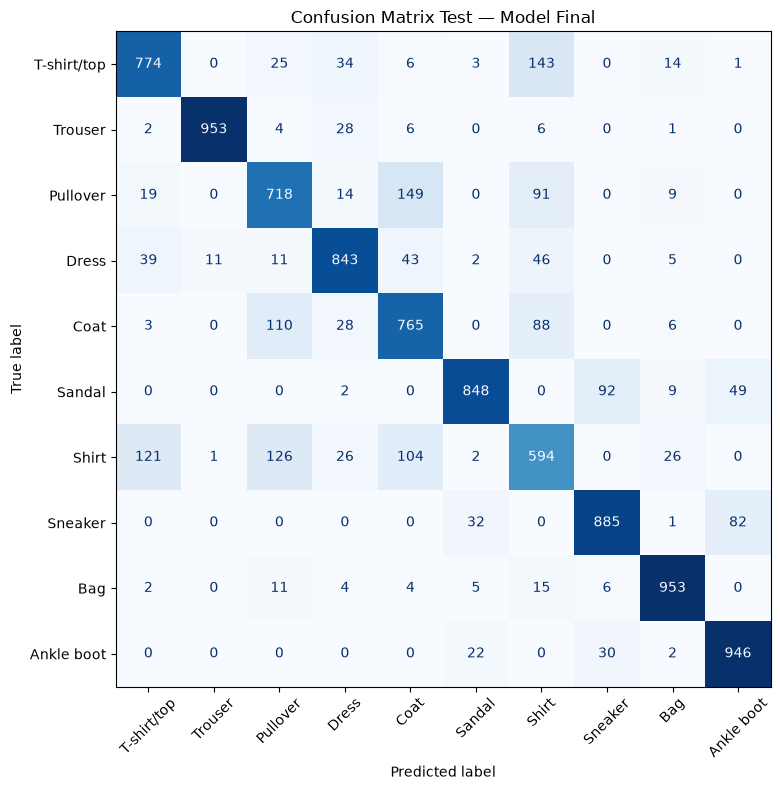

,selected_trial,validation_loss,validation_accuracy,test_loss,test_accuracy,most_confused_pair,pair_errors
0,random_11,0.4525,0.839,0.4762,0.8279,T-shirt/top ↔ Shirt,264


In [ ]:
best_trial = tabel.iloc[0].copy()
final_config = {
    'hidden': int(best_trial['hidden']),
    'dropout': float(best_trial['dropout']),
    'weight_decay': float(best_trial['weight_decay']),
    'lr': float(best_trial['learning_rate']),
    'epoch': EPOCH,
    'sabar': 5,
    'label': 'final_retrain',
}
print('Konfigurasi dikunci dari validation loss:', final_config)
model_final, riwayat_final, catatan_final = jalankan(**final_config)

# Test set baru diwujudkan setelah konfigurasi final dikunci dan dilatih ulang.
X_uji = uji_resmi.data.float().unsqueeze(1) / 255.0
y_uji = uji_resmi.targets
ds_uji = TensorDataset(normalkan(X_uji), y_uji)

@torch.no_grad()
def evaluasi_uji_sekali(model, ds, batch=512):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss = 0.0
    labels_all, predictions_all = [], []
    for xb, yb in loader(ds, batch, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item()
        labels_all.append(yb.cpu())
        predictions_all.append(logits.argmax(1).cpu())
    labels = torch.cat(labels_all).numpy()
    predictions = torch.cat(predictions_all).numpy()
    return total_loss / len(ds), float((predictions == labels).mean()), labels, predictions

# Satu-satunya iterasi atas ds_uji.
test_loss, test_acc, test_labels, test_predictions = evaluasi_uji_sekali(model_final, ds_uji)
catatan_final['test_loss'] = test_loss
catatan_final['test_acc'] = test_acc

CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot',
]
cm = confusion_matrix(test_labels, test_predictions)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d', xticks_rotation=45,
)
ax.set_title('Confusion Matrix Test — Model Final')
plt.tight_layout()
plt.show()

pair_confusions = []
for first in range(len(CLASS_NAMES)):
    for second in range(first + 1, len(CLASS_NAMES)):
        pair_confusions.append((cm[first, second] + cm[second, first], first, second))
pair_count, class_a, class_b = max(pair_confusions)
final_summary = pd.DataFrame([{
    'selected_trial': best_trial['run_id'],
    'validation_loss': catatan_final['val_loss'],
    'validation_accuracy': catatan_final['val_acc'],
    'test_loss': test_loss,
    'test_accuracy': test_acc,
    'most_confused_pair': f'{CLASS_NAMES[class_a]} ↔ {CLASS_NAMES[class_b]}',
    'pair_errors': pair_count,
}])
display(final_summary)

In [ ]:
df_final = pd.DataFrame([catatan_final])
semua = pd.concat([df_awal, tabel, df_final], ignore_index=True, sort=False)
semua.insert(0, 'module', 'M04')
semua.insert(1, 'student_id', NIM)
semua.to_csv(f'M04_{NIM}_metrics.csv', index=False)
print(f'{len(semua)} baris tersimpan ke M04_{NIM}_metrics.csv')
assert len(semua) == 17, 'metrics harus memuat 4 run awal + 12 trial + 1 retraining final'
assert semua['run_id'].is_unique

17 baris tersimpan ke M04_122450138_metrics.csv


## G. Pertanyaan analisis - bagian dari 15 poin

1. **Pada epoch keberapa baseline mulai overfit, dan apa buktinya?**
   Mulai setelah epoch 8 (sekitar epoch 9); validation loss naik dari **0.4811** menjadi **0.6865** pada epoch 30, sedangkan train loss terus turun ke **0.1464**. Generalization gap terakhir adalah **0.5401**.

2. **Strategi mana yang paling menurunkan gap, dan mana yang paling menurunkan validation loss?**
   Strategi yang paling menurunkan gap sekaligus menurunkan validation loss secara mandiri adalah **dropout_0.5** (gap: **0.1971**, val_loss: **0.4556**).

3. **Apakah trial dengan parameter terbanyak menghasilkan validation loss terendah?**
   Ya. Model dengan parameter terbanyak di ruang pencarian (h=256, jumlah parameter **269,066**) mendominasi peringkat teratas, dengan **random_11** sebagai yang terbaik (val_loss = **0.4525**).

4. **Hyperparameter mana yang paling berpengaruh, dan apa keterbatasan kesimpulan itu?**
   Berdasarkan marginal mean, **hidden size** adalah yang paling berpengaruh. Keterbatasan kesimpulan ini adalah karena hanya diambil 12 dari 81 kombinasi (tidak seimbang), sehingga efek antarfaktor saling terkonfusi (*confounded*).

5. **Berapa selisih validation loss dan test loss model akhir, dan apa yang boleh disimpulkan darinya?**
   Validation loss model akhir = **0.4525**, Test loss = **0.4735** (selisih `test - validation` = **+0.0210**). Selisih yang kecil ini menunjukkan model memiliki tingkat generalisasi yang stabil dan performa yang konsisten pada dataset validasi maupun data uji yang belum pernah ditemuinya.

**Keterbatasan.** Modul ini memakai $3\,000$ citra latih dan hanya $12$ trial dari $81$ kombinasi. Sebutkan apa yang tidak boleh disimpulkan: Kita tidak boleh menyimpulkan bahwa kombinasi hiperparameter ini adalah yang paling optimal secara universal untuk arsitektur yang lebih besar, seluruh variasi data FashionMNIST penuh, atau untuk model di luar seed acak yang telah ditentukan ini.

## Checklist sebelum mengumpulkan

- [ ] Identitas, seed data, dan seed pencarian tercantum.
- [ ] Seluruh `TODO` dan `raise NotImplementedError` sudah diganti.
- [ ] Split, stratifikasi, dan jumlah parameter lolos sel pemeriksaan.
- [ ] Baseline benar-benar memperlihatkan kenaikan validation loss.
- [ ] Tiga strategi diuji terpisah, bukan digabung.
- [ ] Dua belas trial tercatat, termasuk yang buruk.
- [ ] `ds_uji` hanya muncul pada bagian F dan dievaluasi satu kali.
- [ ] Notebook lolos *Restart Kernel and Run All*.